# ConvNeXt-Large Training - Biological 5-Fold Cross Validation

Train one independent model per biological fold exported by `ImageFolder_Biolgical_split.ipynb`. Existing `fold_1` ... `fold_5` train/validation directories are used directly; timestamps from a biological sample stay together.

The training settings match `model-setting.ipynb`. Final fold evaluation uses last-epoch EMA weights; best-AUC checkpoints are retained separately.


In [1]:
from __future__ import annotations

from dataclasses import dataclass
from hashlib import sha1
from pathlib import Path
import json
import math
import os
import random
import shutil
import sys
import time

import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.cuda.amp import GradScaler, autocast
from torch.utils.data import DataLoader, Dataset
from torchvision.datasets import ImageFolder
from tqdm.auto import tqdm
from PIL import Image
from timm import create_model
from timm.utils import ModelEmaV2


def find_repo_root() -> Path:
    candidate = Path.cwd().resolve()
    while candidate != candidate.parent and not (candidate / "pyproject.toml").exists():
        candidate = candidate.parent
    if not (candidate / "pyproject.toml").exists():
        raise FileNotFoundError("Could not locate the repository root containing pyproject.toml.")
    return candidate


repo_root = find_repo_root()
src_dir = repo_root / "src"
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

print(f"Repository root: {repo_root}")
print(f"Torch version:    {torch.__version__}")


/media/capp/TMP2/DeathScope/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Repository root: /media/capp/TMP2/DeathScope
Torch version:    2.10.0+cu128


## Configuration

Default input: `training/ConvNeXt/ImageFolder_Biolgical_split`, generated with `EXPORT_ALL_FOLDS=True`. Set `SPLIT_ROOT` to that notebook's `OUTPUT_ROOT` and `K_FOLDS` to its `N_FOLDS`. `USE_BIOLOGICAL_FOLDS=True` bypasses all source discovery, image copying, and image-level splitting. `SOURCE_DATA_ROOT` is unused in this mode.

Model outputs are saved separately under `RUN_DIR/fold_*`. Training defaults match `model-setting.ipynb`: batch size 48, 50 epochs, five warmup epochs, and EMA 0.9999.


In [2]:
SOURCE_DATA_ROOT = repo_root / "training/ConvNeXt/ImageFolder"  # Copied train/val ImageFolder; pooled for five-fold CV.
RUN_DIR = repo_root / "training/ConvNeXt/5fold_cross_validation"
USE_BIOLOGICAL_FOLDS = True  # Consume exported folds directly; never re-split images.
SPLIT_ROOT = repo_root / "training/ConvNeXt/ImageFolder_Biolgical_split"
# For legacy image-level splitting: set USE_BIOLOGICAL_FOLDS=False and
# set SPLIT_ROOT = RUN_DIR / "ImageFolder_5fold".

IMAGE_PATTERNS = ("*.png", "*.jpg", "*.jpeg", "*.tif", "*.tiff")
K_FOLDS = 5  # Must match N_FOLDS in ImageFolder_Biolgical_split.ipynb.
COPY_FILES = True          # True copies files; False creates symlinks
SEED = 42
REUSE_EXISTING_FOLDS = True

CONVNEXT_MODEL_VARIANTS = {
    "tiny": "convnext_tiny",
    "small": "convnext_small",
    "base": "convnext_base",
    "large": "convnext_large.fb_in22k_ft_in1k",
}
CONVNEXT_MODEL_SIZE = "tiny"  # Options: "tiny", "small", "base", "large"
if CONVNEXT_MODEL_SIZE not in CONVNEXT_MODEL_VARIANTS:
    valid_model_sizes = ", ".join(sorted(CONVNEXT_MODEL_VARIANTS))
    raise ValueError(f"CONVNEXT_MODEL_SIZE must be one of: {valid_model_sizes}")
ARCHITECTURE = CONVNEXT_MODEL_VARIANTS[CONVNEXT_MODEL_SIZE]
IMAGE_SIZE = 48
BATCH_SIZE = 48
EPOCHS = 50
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 5e-2
WARMUP_EPOCHS = 5
EMA_ENABLED = True
EMA_DECAY = 0.9999
MIXUP = 0.0
CUTMIX = 0.0
CONTINUE_TRAINING = False
LABEL_SMOOTHING = 0.05
GRAD_CLIP_NORM = 1.0
NUM_WORKERS = 8
USE_PRETRAINED = True
AMP_ENABLED = True
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

TRAIN_MEAN = (0.5, 0.5, 0.5)
TRAIN_STD = (0.25, 0.25, 0.25)

RUN_DIR.mkdir(parents=True, exist_ok=True)
print(f"Source data root: {SOURCE_DATA_ROOT}")
print(f"Run directory:    {RUN_DIR}")
print(f"Fold split root:  {SPLIT_ROOT}")
print(f"Folds:            {K_FOLDS}")
print(f"ConvNeXt size:    {CONVNEXT_MODEL_SIZE}")
print(f"Architecture:     {ARCHITECTURE}")
print(f"Device:           {DEVICE}")


Source data root: /media/capp/TMP2/DeathScope/training/ConvNeXt/ImageFolder
Run directory:    /media/capp/TMP2/DeathScope/training/ConvNeXt/5fold_cross_validation
Fold split root:  /media/capp/TMP2/DeathScope/training/ConvNeXt/ImageFolder_Biolgical_split
Folds:            5
ConvNeXt size:    tiny
Architecture:     convnext_tiny
Device:           cuda


## Validate Existing Biological Folds

Before training, verify all expected fold directories and biological manifests exist, every sample is held out once, class mappings agree, and exported image counts match the manifests. Missing or incomplete biological exports produce an actionable error; they never fall back to image-level splitting.

For the older image-level workflow, explicitly set `USE_BIOLOGICAL_FOLDS=False` and point `SPLIT_ROOT` to a separate output directory such as `RUN_DIR / "ImageFolder_5fold"`.


In [3]:
IMAGE_SUFFIXES = {pattern.replace("*", "").lower() for pattern in IMAGE_PATTERNS}


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True


set_seed(SEED)


def is_image_file(path: Path) -> bool:
    return path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES


def list_images(directory: Path, recursive: bool = False) -> list[Path]:
    iterator = directory.rglob("*") if recursive else directory.iterdir()
    return sorted([path for path in iterator if is_image_file(path)])


def dataset_has_explicit_split(root: Path) -> bool:
    return (root / "train").is_dir() and (root / "val").is_dir()


def dataset_has_cv_folds(split_root: Path, n_folds: int) -> bool:
    if not split_root.is_dir():
        return False
    for fold_number in range(1, n_folds + 1):
        fold_root = split_root / f"fold_{fold_number}"
        if not dataset_has_explicit_split(fold_root):
            return False
    return True


def class_dirs_from_split(split_dir: Path) -> list[Path]:
    return sorted([path for path in split_dir.iterdir() if path.is_dir()])


def direct_class_dirs(root: Path) -> list[Path]:
    return sorted([path for path in root.iterdir() if path.is_dir() and list_images(path)])


def recursive_class_dirs(root: Path) -> list[Path]:
    return sorted([path for path in root.iterdir() if path.is_dir() and list_images(path, recursive=True)])


def grouped_class_dir_map(root: Path) -> dict[str, list[Path]]:
    grouped: dict[str, list[Path]] = {}
    for dataset_dir in sorted([path for path in root.iterdir() if path.is_dir()]):
        child_class_dirs = [path for path in dataset_dir.iterdir() if path.is_dir() and list_images(path, recursive=True)]
        for class_dir in sorted(child_class_dirs):
            grouped.setdefault(class_dir.name, []).append(class_dir)
    return grouped


def explicit_split_class_dir_map(root: Path) -> dict[str, list[Path]]:
    grouped: dict[str, list[Path]] = {}
    for split_name in ("train", "val"):
        for class_dir in class_dirs_from_split(root / split_name):
            if list_images(class_dir, recursive=True):
                grouped.setdefault(class_dir.name, []).append(class_dir)
    return grouped


def collect_source_class_dirs(root: Path) -> tuple[dict[str, list[Path]], str]:
    if dataset_has_explicit_split(root):
        return explicit_split_class_dir_map(root), "explicit_split"

    flat_dirs = direct_class_dirs(root)
    if flat_dirs:
        return {path.name: [path] for path in flat_dirs}, "flat"

    grouped_dirs = grouped_class_dir_map(root)
    if len(grouped_dirs) == 2:
        return grouped_dirs, "grouped_recursive"

    nested_class_dirs = recursive_class_dirs(root)
    if len(nested_class_dirs) == 2:
        return {path.name: [path] for path in nested_class_dirs}, "class_first_recursive"

    raise ValueError(
        f"Could not infer a supported dataset layout under {root}. Expected flat class folders, recursive class folders, grouped class folders, a dataset-container root, or a pre-split ImageFolder layout."
    )


def validate_binary_classes(class_names: list[str]) -> None:
    if len(class_names) != 2:
        raise ValueError(
            f"This notebook is intended for the binary ConvNeXt classifier and expects exactly 2 classes, found {class_names}."
        )


def unique_name(src_path: Path, label: str) -> str:
    digest = sha1(str(src_path.resolve()).encode("utf-8")).hexdigest()[:8]
    return f"{src_path.stem}_{label}_{digest}{src_path.suffix.lower()}"


def build_stratified_fold_assignments(
    class_dir_map: dict[str, list[Path]],
    n_folds: int,
    seed: int,
) -> dict[int, dict[str, dict[str, list[Path]]]]:
    assignments = {
        fold_number: {"train": {}, "val": {}}
        for fold_number in range(1, n_folds + 1)
    }
    rng = random.Random(seed)

    for class_name in sorted(class_dir_map):
        images: list[Path] = []
        for class_dir in class_dir_map[class_name]:
            images.extend(list_images(class_dir, recursive=True))
        images = sorted(images)
        if len(images) < n_folds:
            raise ValueError(
                f"Need at least {n_folds} images for class '{class_name}' to create {n_folds} stratified folds; found {len(images)}."
            )

        shuffled = images[:]
        rng.shuffle(shuffled)
        buckets = [[] for _ in range(n_folds)]
        for image_index, image_path in enumerate(shuffled):
            buckets[image_index % n_folds].append(image_path)

        for fold_index in range(n_folds):
            fold_number = fold_index + 1
            val_files = sorted(buckets[fold_index])
            train_files = sorted(
                image_path
                for bucket_index, bucket in enumerate(buckets)
                if bucket_index != fold_index
                for image_path in bucket
            )
            assignments[fold_number]["train"][class_name] = train_files
            assignments[fold_number]["val"][class_name] = val_files

    return assignments


def materialize_files(files: list[Path], out_dir: Path, class_name: str, copy_files: bool) -> None:
    out_dir.mkdir(parents=True, exist_ok=True)
    for src in files:
        dst = out_dir / unique_name(src, class_name)
        if dst.exists():
            continue
        if copy_files:
            shutil.copy2(src, dst)
        else:
            os.symlink(src.resolve(), dst)


def materialize_fold_splits(
    source_root: Path,
    split_root: Path,
    n_folds: int,
    copy_files: bool,
    seed: int,
    reuse_existing: bool,
) -> tuple[Path, list[str], str]:
    class_dir_map, source_layout = collect_source_class_dirs(source_root)
    class_names = sorted(class_dir_map)
    validate_binary_classes(class_names)

    if split_root.exists() and reuse_existing and dataset_has_cv_folds(split_root, n_folds):
        return split_root, class_names, source_layout

    if split_root.exists() and not reuse_existing:
        shutil.rmtree(split_root)

    assignments = build_stratified_fold_assignments(class_dir_map, n_folds, seed)
    manifest_records = []
    for fold_number, fold_payload in assignments.items():
        fold_root = split_root / f"fold_{fold_number}"
        for split_name in ("train", "val"):
            for class_name, files in fold_payload[split_name].items():
                materialize_files(files, fold_root / split_name / class_name, class_name, copy_files)
                for src in files:
                    manifest_records.append({
                        "fold": fold_number,
                        "split": split_name,
                        "class_name": class_name,
                        "source_path": str(src),
                        "materialized_name": unique_name(src, class_name),
                    })

    pd.DataFrame(manifest_records).to_csv(split_root / "fold_assignments.csv", index=False)
    return split_root, class_names, source_layout


def validate_biological_folds(split_root: Path, n_folds: int) -> list[str]:
    if not dataset_has_cv_folds(split_root, n_folds):
        missing = [f"fold_{number}" for number in range(1, n_folds + 1)
                   if not dataset_has_explicit_split(split_root / f"fold_{number}")]
        raise FileNotFoundError(
            f"Missing biological folds under {split_root}: {missing}. "
            "Run ImageFolder_Biolgical_split.ipynb with EXPORT_ALL_FOLDS=True "
            "and N_FOLDS matching K_FOLDS, then set SPLIT_ROOT to its OUTPUT_ROOT."
        )
    class_names = None
    reference_samples = None
    validation_samples = set()
    for number in range(1, n_folds + 1):
        fold_root = split_root / f"fold_{number}"
        config_path = fold_root / "split_config.json"
        manifest_path = fold_root / "biological_sample_manifest.csv"
        if not config_path.is_file() or not manifest_path.is_file():
            raise FileNotFoundError(
                f"Biological split metadata missing in {fold_root}. "
                "Use the complete output from ImageFolder_Biolgical_split.ipynb."
            )
        split_config = json.loads(config_path.read_text(encoding="utf-8"))
        if split_config.get("n_folds") != n_folds or split_config.get("validation_fold") != number:
            raise ValueError(f"Fold metadata does not match K_FOLDS={n_folds} / fold {number}: {config_path}")
        manifest = pd.read_csv(manifest_path, dtype={"sample_id": str, "class_name": str})
        required = {"sample_id", "class_name", "validation_fold", "split", "images"}
        if not required.issubset(manifest.columns):
            raise ValueError(f"Missing biological manifest columns in {manifest_path}: {sorted(required - set(manifest.columns))}")
        if manifest[list(required)].isna().any().any() or manifest["sample_id"].duplicated().any():
            raise ValueError(f"Missing values or duplicate biological samples in {manifest_path}")
        assignments = pd.to_numeric(manifest["validation_fold"], errors="raise")
        if not assignments.isin(range(1, n_folds + 1)).all():
            raise ValueError(f"Invalid validation fold assignments in {manifest_path}")
        expected_splits = assignments.map(lambda assigned: "val" if assigned == number else "train")
        if not manifest["split"].equals(expected_splits):
            raise ValueError(f"Biological sample split disagrees with fold assignment in {manifest_path}")
        sample_plan = set(zip(manifest["sample_id"], manifest["class_name"], assignments))
        if reference_samples is None:
            reference_samples = sample_plan
        elif sample_plan != reference_samples:
            raise ValueError(f"Biological sample assignments differ across folds: {manifest_path}")
        train_ids = set(manifest.loc[manifest["split"] == "train", "sample_id"])
        val_ids = set(manifest.loc[manifest["split"] == "val", "sample_id"])
        if train_ids & val_ids or validation_samples & val_ids:
            raise ValueError(f"Biological sample leakage detected in fold {number}")
        validation_samples.update(val_ids)
        image_counts = pd.to_numeric(manifest["images"], errors="raise")
        if (image_counts <= 0).any() or (image_counts % 1 != 0).any():
            raise ValueError(f"Invalid biological sample image counts in {manifest_path}")
        for split_name in ("train", "val"):
            dataset = ImageFolder(root=str(fold_root / split_name))
            validate_binary_classes(dataset.classes)
            if class_names is None:
                class_names = dataset.classes
            if dataset.classes != class_names or set(manifest["class_name"]) != set(class_names):
                raise ValueError(f"Class mapping differs in {fold_root}/{split_name}")
            for label, index in dataset.class_to_idx.items():
                mask = (manifest["split"] == split_name) & (manifest["class_name"] == label)
                expected = int(image_counts[mask].sum())
                actual = dataset.targets.count(index)
                if actual != expected:
                    raise ValueError(
                        f"Incomplete biological export in {fold_root}/{split_name}/{label}: "
                        f"expected {expected} images, found {actual}. Finish exporting all folds."
                    )
    if validation_samples != {sample_id for sample_id, _label, _fold in reference_samples}:
        raise ValueError("Each biological sample must appear in validation exactly once across folds.")
    print(f"Verified {n_folds} biological folds: no train/val sample overlap; every sample is held out once.")
    return class_names


def resolve_fold_dataset(source_root: Path, split_root: Path) -> tuple[Path, list[str], str]:
    if USE_BIOLOGICAL_FOLDS:
        class_names = validate_biological_folds(split_root, K_FOLDS)
        return split_root, class_names, "biological_folds"
    # Reuse copied fold directories even when the original source is unavailable.
    if REUSE_EXISTING_FOLDS and dataset_has_cv_folds(split_root, K_FOLDS):
        class_names = ImageFolder(root=str(split_root / "fold_1" / "train")).classes
        validate_binary_classes(class_names)
        for fold_number in range(1, K_FOLDS + 1):
            for split_name in ("train", "val"):
                dataset = ImageFolder(root=str(split_root / f"fold_{fold_number}" / split_name))
                if dataset.classes != class_names:
                    raise ValueError(f"Class mismatch in fold {fold_number}/{split_name}")
        return split_root, class_names, "existing_folds"
    if not source_root.exists():
        raise FileNotFoundError(f"Dataset root not found: {source_root}")
    return materialize_fold_splits(
        source_root=source_root,
        split_root=split_root,
        n_folds=K_FOLDS,
        copy_files=COPY_FILES,
        seed=SEED,
        reuse_existing=REUSE_EXISTING_FOLDS,
    )


def summarize_source_root(source_root: Path, source_layout: str) -> pd.DataFrame:
    records = []
    if source_layout == "explicit_split":
        for split_name in ("train", "val"):
            for class_dir in class_dirs_from_split(source_root / split_name):
                records.append({
                    "source_group": split_name,
                    "class_name": class_dir.name,
                    "count": len(list_images(class_dir, recursive=True)),
                })
    elif source_layout == "grouped_recursive":
        grouped_dirs = grouped_class_dir_map(source_root)
        for class_name, class_dirs in sorted(grouped_dirs.items()):
            for class_dir in class_dirs:
                records.append({
                    "source_group": class_dir.parent.name,
                    "class_name": class_name,
                    "count": len(list_images(class_dir, recursive=True)),
                })
    elif source_layout in {"flat", "class_first_recursive"}:
        for class_dir in recursive_class_dirs(source_root):
            records.append({
                "source_group": source_root.name,
                "class_name": class_dir.name,
                "count": len(list_images(class_dir, recursive=True)),
            })
    return pd.DataFrame(records)


def summarize_folds(split_root: Path, n_folds: int) -> pd.DataFrame:
    records = []
    for fold_number in range(1, n_folds + 1):
        fold_root = split_root / f"fold_{fold_number}"
        for split_name in ("train", "val"):
            split_dir = fold_root / split_name
            for class_dir in class_dirs_from_split(split_dir):
                records.append({
                    "fold": fold_number,
                    "split": split_name,
                    "class_name": class_dir.name,
                    "count": len(list_images(class_dir)),
                })
    return pd.DataFrame(records)


fold_split_root, class_names, source_layout = resolve_fold_dataset(SOURCE_DATA_ROOT, SPLIT_ROOT)
fold_roots = [fold_split_root / f"fold_{fold_number}" for fold_number in range(1, K_FOLDS + 1)]
class_to_idx = {name: index for index, name in enumerate(class_names)}
idx_to_class = {index: name for name, index in class_to_idx.items()}

with (RUN_DIR / "classes.json").open("w", encoding="utf-8") as file:
    json.dump({"class_to_idx": class_to_idx, "idx_to_class": idx_to_class}, file, indent=2)

if source_layout not in {"existing_folds", "biological_folds"}:
    source_summary = summarize_source_root(SOURCE_DATA_ROOT, source_layout)
    if not source_summary.empty:
        display(source_summary)

fold_summary = summarize_folds(fold_split_root, K_FOLDS)
display(fold_summary)
print(f"Using fold split root: {fold_split_root}")
print(f"Detected source layout: {source_layout}")
print(f"Class mapping: {idx_to_class}")


Verified 5 biological folds: no train/val sample overlap; every sample is held out once.


,fold,split,class_name,count
0,1,train,apoptosis,36918
1,1,train,pyroptosis,45045
2,1,val,apoptosis,7187
3,1,val,pyroptosis,11340
4,2,train,apoptosis,33232
5,2,train,pyroptosis,46582
6,2,val,apoptosis,10873
7,2,val,pyroptosis,9803
8,3,train,apoptosis,35482
9,3,train,pyroptosis,45933


Using fold split root: /media/capp/TMP2/DeathScope/training/ConvNeXt/ImageFolder_Biolgical_split
Detected source layout: biological_folds
Class mapping: {0: 'apoptosis', 1: 'pyroptosis'}


## Transforms And Dataloaders

PIL RGB loading, ImageFolder sample ordering, augmentation, normalization, eight workers, and `drop_last=True` match `model-setting.ipynb`. Each fold uses the reference's global RNG behavior without a separate loader generator or custom worker seeding.


In [4]:
def build_transforms(img_size):
    train_tf = A.Compose([
        A.RandomResizedCrop(img_size, img_size, scale=(0.8, 1.0), ratio=(0.9, 1.1)),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.ShiftScaleRotate(
            shift_limit=0.05,
            scale_limit=0.1,
            rotate_limit=45,
            border_mode=cv2.BORDER_REFLECT_101,  # safe default
            p=0.7
        ),
        A.OneOf([
            A.GaussianBlur(blur_limit=(3,7), p=1.0),
            A.GaussNoise(var_limit=(5.0, 25.0), p=1.0),
        ], p=0.3),
        A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, p=0.5),
        A.CLAHE(clip_limit=(1,4), tile_grid_size=(8,8), p=0.3),
        A.Normalize(mean=(0.5,0.5,0.5), std=(0.25,0.25,0.25)),
        ToTensorV2(),
    ])
    val_tf = A.Compose([
        A.LongestMaxSize(max_size=img_size),
        A.PadIfNeeded(img_size, img_size, border_mode=cv2.BORDER_REFLECT_101),
        A.Normalize(mean=(0.5,0.5,0.5), std=(0.25,0.25,0.25)),
        ToTensorV2(),
    ])
    return train_tf, val_tf

def load_rgb_image(image_path: Path) -> np.ndarray:
    # Match torchvision ImageFolder's default PIL RGB loader.
    with image_path.open("rb") as file:
        with Image.open(file) as image:
            return np.array(image.convert("RGB"))



class ConvNeXtImageFolderDataset(Dataset):
    def __init__(self, split_dir: Path, class_to_idx: dict[str, int], transform: A.Compose):
        self.split_dir = Path(split_dir)
        self.class_to_idx = dict(class_to_idx)
        self.transform = transform
        self.samples = self._collect_samples()

    def _collect_samples(self) -> list[tuple[Path, int]]:
        # Use the reference's ImageFolder enumeration and class ordering exactly.
        image_folder = ImageFolder(root=str(self.split_dir))
        if image_folder.class_to_idx != self.class_to_idx:
            raise ValueError("Train and validation class mappings must match ImageFolder ordering.")
        return [(Path(path), target) for path, target in image_folder.samples]

    def __len__(self) -> int:
        return len(self.samples)

    def __getitem__(self, index: int):
        image_path, target = self.samples[index]
        image = load_rgb_image(image_path)
        tensor = self.transform(image=image)["image"].float()
        return tensor, target, str(image_path)


def build_fold_dataloaders(fold_root: Path, fold_seed: int):
    # Match reference RNG behavior: global seed, no separate loader generator
    # or custom worker initialization. Reset transforms independently per fold.
    train_transform, val_transform = build_transforms(IMAGE_SIZE)
    train_ds = ConvNeXtImageFolderDataset(fold_root / "train", class_to_idx, train_transform)
    val_ds = ConvNeXtImageFolderDataset(fold_root / "val", class_to_idx, val_transform)
    train_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
        pin_memory=True, drop_last=True,
    )
    val_loader = DataLoader(
        val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
        pin_memory=True, drop_last=False,
    )
    return train_loader, val_loader, train_ds, val_ds


fold_size_records = []
for fold_number, fold_root in enumerate(fold_roots, start=1):
    fold_size_records.append({
        "fold": fold_number,
        "train_samples": len(ImageFolder(root=str(fold_root / "train"))),
        "val_samples": len(ImageFolder(root=str(fold_root / "val"))),
    })
display(pd.DataFrame(fold_size_records))


,fold,train_samples,val_samples
0,1,81963,18527
1,2,79814,20676
2,3,81415,19075
3,4,78061,22429
4,5,80707,19783


## Model And Training Utilities

Each fold saves:
- `fold_*/model_best.pth`
- `fold_*/checkpoint_last.pth`
- `fold_*/history.json`
- `fold_*/history.csv`
- `fold_*/final_metrics.json`

The cross-validation root also saves `classes.json`, `config.json`, `history_all_folds.csv`, `fold_best_metrics.csv`, `cross_validation_metrics.json`, and `validation_predictions_all_folds.csv`.


In [5]:
@dataclass
class EpochMetrics:
    loss: float
    acc: float
    f1: float
    auc: float


def binary_auc_score(targets: np.ndarray, positive_scores: np.ndarray) -> float:
    targets = np.asarray(targets, dtype=np.int64)
    positive_scores = np.asarray(positive_scores, dtype=np.float64)
    positives = int((targets == 1).sum())
    negatives = int((targets == 0).sum())
    if positives == 0 or negatives == 0:
        return float("nan")

    order = np.argsort(positive_scores, kind="mergesort")
    sorted_scores = positive_scores[order]
    ranks = np.zeros(len(sorted_scores), dtype=np.float64)

    start = 0
    while start < len(sorted_scores):
        stop = start + 1
        while stop < len(sorted_scores) and sorted_scores[stop] == sorted_scores[start]:
            stop += 1
        average_rank = (start + stop - 1) / 2.0 + 1.0
        ranks[order[start:stop]] = average_rank
        start = stop

    positive_ranks = ranks[targets == 1].sum()
    return float((positive_ranks - positives * (positives + 1) / 2.0) / (positives * negatives))


def confusion_counts(targets: np.ndarray, preds: np.ndarray) -> tuple[int, int, int, int]:
    targets = np.asarray(targets, dtype=np.int64)
    preds = np.asarray(preds, dtype=np.int64)
    tp = int(((targets == 1) & (preds == 1)).sum())
    tn = int(((targets == 0) & (preds == 0)).sum())
    fp = int(((targets == 0) & (preds == 1)).sum())
    fn = int(((targets == 1) & (preds == 0)).sum())
    return tp, tn, fp, fn


def compute_epoch_metrics(targets: list[int], preds: list[int], probs: list[float], loss_sum: float, sample_count: int) -> EpochMetrics:
    targets_np = np.asarray(targets, dtype=np.int64)
    preds_np = np.asarray(preds, dtype=np.int64)
    probs_np = np.asarray(probs, dtype=np.float64)
    accuracy = float((targets_np == preds_np).mean()) if len(targets_np) else float("nan")
    tp, tn, fp, fn = confusion_counts(targets_np, preds_np)
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    auc = binary_auc_score(targets_np, probs_np)
    return EpochMetrics(
        loss=float(loss_sum / max(sample_count, 1)),
        acc=accuracy,
        f1=float(f1),
        auc=float(auc),
    )


def train_one_epoch(model, loader, optimizer, scaler, device, epoch, mixup_fn=None, loss_fn=None, grad_clip=None, model_ema=None, scheduler=None):
    model.train()
    loss_meter, n_samples = 0.0, 0
    preds_all, targets_all = [], []
    start = time.time()

    for imgs, labels, _paths in tqdm(loader, desc=f"Train {epoch}", leave=False):
        imgs = imgs.to(device, non_blocking=True).float()
        labels = labels.to(device, non_blocking=True)

        # Binary -> 2-class one-hot for SoftTarget CE with mixup
        labels_onehot = torch.nn.functional.one_hot(labels, num_classes=2).float()

        if mixup_fn is not None:
            imgs, labels_onehot = mixup_fn(imgs, labels_onehot)

        optimizer.zero_grad(set_to_none=True)
        with autocast(enabled=True):
            logits = model(imgs)
            loss = loss_fn(logits, labels)

        scaler.scale(loss).backward()
        if grad_clip:
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
        scaler.step(optimizer)
        scaler.update()
        if scheduler and hasattr(scheduler, "step"):
            scheduler.step()

        loss_meter += loss.item() * imgs.size(0)
        n_samples += imgs.size(0)

        with torch.no_grad():
            probs = torch.softmax(logits, dim=1)[:,1].detach().cpu().numpy()
            if mixup_fn is None:
                preds_all.extend((probs > 0.5).astype(int).tolist())
                targets_all.extend(labels.detach().cpu().numpy().tolist())
            else:
                # Can't compute accuracy properly on mixed labels; skip per-step metrics
                pass

        if model_ema is not None:
            model_ema.update(model)

    avg_loss = loss_meter / max(1, n_samples)
    metrics = {}
    if mixup_fn is None and len(targets_all) > 0:
        metrics["acc"] = float((np.asarray(targets_all) == np.asarray(preds_all)).mean())
        metrics["f1"]  = compute_epoch_metrics(targets_all, preds_all, [0.0] * len(targets_all), 0.0, len(targets_all)).f1

    return avg_loss, metrics, time.time()-start

@torch.no_grad()
def validate(model, loader, device, use_ema=False, model_ema=None):
    model.eval()
    if use_ema and model_ema is not None:
        model = model_ema.module

    loss_fn = nn.CrossEntropyLoss()
    loss_meter, n_samples = 0.0, 0
    probs_all, preds_all, targets_all = [], [], []

    for imgs, labels, _paths in tqdm(loader, desc="Validate", leave=False):
        imgs = imgs.to(device, non_blocking=True).float()
        labels = labels.to(device, non_blocking=True)
        logits = model(imgs)
        loss = loss_fn(logits, labels)
        loss_meter += loss.item() * imgs.size(0)
        n_samples += imgs.size(0)

        probs = torch.softmax(logits, dim=1)[:,1].cpu().numpy()
        preds = (probs > 0.5).astype(int)
        probs_all.extend(probs.tolist())
        preds_all.extend(preds.tolist())
        targets_all.extend(labels.cpu().numpy().tolist())

    avg_loss = loss_meter / max(1, n_samples)
    acc = float((np.asarray(targets_all) == np.asarray(preds_all)).mean())
    f1  = compute_epoch_metrics(targets_all, preds_all, [0.0] * len(targets_all), 0.0, len(targets_all)).f1
    try:
        auc = binary_auc_score(np.asarray(targets_all), np.asarray(probs_all))
    except Exception:
        auc = float("nan")
    return avg_loss, acc, f1, auc, preds_all, probs_all, targets_all


def build_model(architecture: str, num_classes: int, pretrained: bool) -> nn.Module:
    model = create_model(architecture, pretrained=pretrained, num_classes=num_classes)
    return model


def save_checkpoint(path: Path, model: nn.Module, optimizer, scheduler, epoch: int, metrics: dict, config: dict, scaler=None, model_ema=None):
    payload = {
        "epoch": epoch,
        "model": model.state_dict(),
        "model_ema": model_ema.module.state_dict() if model_ema is not None else None,
        "scaler": scaler.state_dict() if scaler is not None else None,
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict() if scheduler is not None else None,
        "metrics": metrics,
        "config": config,
    }
    torch.save(payload, path)


def load_checkpoint(path: Path, device: torch.device):
    if not path.is_file():
        raise FileNotFoundError(f"Checkpoint not found: {path}")
    return torch.load(path, map_location=device)


def is_better(candidate: dict, best: dict | None) -> bool:
    if best is None:
        return True
    candidate_key = (
        float("-inf") if math.isnan(candidate["val_auc"]) else candidate["val_auc"],
        candidate["val_f1"],
        candidate["val_acc"],
        -candidate["val_loss"],
    )
    best_key = (
        float("-inf") if math.isnan(best["val_auc"]) else best["val_auc"],
        best["val_f1"],
        best["val_acc"],
        -best["val_loss"],
    )
    return candidate_key > best_key


## Train

This cell trains one independent ConvNeXt-Large model for each fold. Checkpoints and fold histories are written under `RUN_DIR/fold_1` through `RUN_DIR/fold_5`, and combined fold histories are written at the cross-validation root.


In [6]:
device = torch.device(DEVICE)
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)

base_config_payload = {
    "source_data_root": str(SOURCE_DATA_ROOT),
    "fold_split_root": str(fold_split_root),
    "run_dir": str(RUN_DIR),
    "class_to_idx": class_to_idx,
    "architecture": ARCHITECTURE,
    "convnext_model_size": CONVNEXT_MODEL_SIZE,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "k_folds": K_FOLDS,
    "split_mode": source_layout,
    "use_biological_folds": USE_BIOLOGICAL_FOLDS,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "label_smoothing": LABEL_SMOOTHING,
    "grad_clip_norm": GRAD_CLIP_NORM,
    "warmup_epochs": WARMUP_EPOCHS,
    "ema_enabled": EMA_ENABLED,
    "ema_decay": EMA_DECAY,
    "mixup": MIXUP,
    "cutmix": CUTMIX,
    "num_workers": NUM_WORKERS,
    "amp_enabled": AMP_ENABLED,
    "use_pretrained": USE_PRETRAINED,
    "train_mean": TRAIN_MEAN,
    "train_std": TRAIN_STD,
    "final_evaluation": "last_epoch_ema",
    "seed": SEED,
    "device": DEVICE,
}
with (RUN_DIR / "config.json").open("w", encoding="utf-8") as file:
    json.dump(base_config_payload, file, indent=2)

cv_history = []
fold_best_records = []
start_time = time.time()

for fold_number, fold_root in enumerate(fold_roots, start=1):
    fold_run_dir = RUN_DIR / f"fold_{fold_number}"
    fold_run_dir.mkdir(parents=True, exist_ok=True)
    fold_seed = SEED
    set_seed(fold_seed)

    train_loader, val_loader, train_ds, val_ds = build_fold_dataloaders(fold_root, fold_seed=fold_seed)
    model = build_model(ARCHITECTURE, num_classes=len(class_names), pretrained=USE_PRETRAINED).to(device)
    model_ema = ModelEmaV2(model, decay=EMA_DECAY, device=device) if EMA_ENABLED else None
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY, betas=(0.9, 0.999))
    n_steps_per_epoch = len(train_loader)
    if n_steps_per_epoch == 0:
        raise ValueError("Training dataset must contain at least BATCH_SIZE samples with drop_last=True.")
    total_steps = EPOCHS * n_steps_per_epoch
    warmup_steps = WARMUP_EPOCHS * n_steps_per_epoch
    
    def lr_lambda(step):
        if step < warmup_steps:
            return float(step) / float(max(1, warmup_steps))
        progress = (step - warmup_steps) / float(max(1, total_steps - warmup_steps))
        return 0.1 + 0.9 * 0.5 * (1.0 + math.cos(math.pi * progress))
    
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    scaler = GradScaler(enabled=AMP_ENABLED and device.type == "cuda")

    fold_config_payload = dict(base_config_payload)
    fold_config_payload.update({
        "fold": fold_number,
        "fold_seed": fold_seed,
        "fold_root": str(fold_root),
        "fold_run_dir": str(fold_run_dir),
        "train_samples": len(train_ds),
        "val_samples": len(val_ds),
    })
    with (fold_run_dir / "config.json").open("w", encoding="utf-8") as file:
        json.dump(fold_config_payload, file, indent=2)

    history = []
    best_record = None
    start_epoch = 1
    resume_checkpoint = fold_run_dir / "checkpoint_last.pth"

    if CONTINUE_TRAINING:
        if resume_checkpoint.is_file():
            checkpoint_payload = load_checkpoint(resume_checkpoint, device)
            model.load_state_dict(checkpoint_payload["model"])
            optimizer.load_state_dict(checkpoint_payload["optimizer"])
            if checkpoint_payload.get("scaler") is not None:
                scaler.load_state_dict(checkpoint_payload["scaler"])
            if model_ema is not None:
                if checkpoint_payload.get("model_ema") is None:
                    raise ValueError("Resume checkpoint has no EMA weights; start a fresh run to match the reference.")
                model_ema.module.load_state_dict(checkpoint_payload["model_ema"])
            if scheduler is not None and checkpoint_payload.get("scheduler") is not None:
                scheduler.load_state_dict(checkpoint_payload["scheduler"])
            start_epoch = int(checkpoint_payload["epoch"]) + 1
            history_path = fold_run_dir / "history.json"
            if history_path.is_file():
                with history_path.open("r", encoding="utf-8") as file:
                    history = json.load(file)
            for record in history:
                best_record = dict(record) if is_better(record, best_record) else best_record
            print(f"Fold {fold_number}: resuming training from epoch {start_epoch} using {resume_checkpoint}")
        else:
            print(f"Fold {fold_number}: CONTINUE_TRAINING=True but no checkpoint was found; starting from scratch.")

    if start_epoch > EPOCHS:
        print(f"Fold {fold_number}: checkpoint epoch {start_epoch - 1} already reaches or exceeds EPOCHS={EPOCHS}; skipping train loop.")

    fold_start_time = time.time()
    for epoch in range(start_epoch, EPOCHS + 1):
        epoch_start = time.time()
        train_loss, train_metrics, _ = train_one_epoch(
            model, train_loader, optimizer, scaler, device, epoch,
            mixup_fn=None, loss_fn=criterion, grad_clip=GRAD_CLIP_NORM,
            model_ema=model_ema, scheduler=scheduler,
        )
        val_loss, val_acc, val_f1, val_auc, val_preds, val_probs, val_targets = validate(
            model, val_loader, device, use_ema=EMA_ENABLED, model_ema=model_ema,
        )

        record = {
            "fold": fold_number,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_acc": train_metrics.get("acc"),
            "train_f1": train_metrics.get("f1"),
            "val_loss": val_loss,
            "val_acc": val_acc,
            "val_f1": val_f1,
            "val_auc": val_auc,
            "lr": float(optimizer.param_groups[0]["lr"]),
            "seconds": float(time.time() - epoch_start),
        }
        history.append(record)

        save_checkpoint(
            fold_run_dir / "checkpoint_last.pth",
            model=model,
            optimizer=optimizer,
            scheduler=scheduler,
            epoch=epoch,
            metrics=record,
            config=fold_config_payload,
            scaler=scaler,
            model_ema=model_ema,
        )

        if record["val_auc"] > (best_record["val_auc"] if best_record is not None else -1.0):
            best_record = dict(record)
            save_checkpoint(
                fold_run_dir / "model_best.pth",
                model=model,
                optimizer=optimizer,
                scheduler=scheduler,
                epoch=epoch,
                metrics=record,
                config=fold_config_payload,
                scaler=scaler,
                model_ema=model_ema,
            )

        with (fold_run_dir / "history.json").open("w", encoding="utf-8") as file:
            json.dump(history, file, indent=2)
        pd.DataFrame(history).to_csv(fold_run_dir / "history.csv", index=False)

        print(
            f"Fold {fold_number}/{K_FOLDS} | Epoch {epoch:03d}/{EPOCHS:03d} | "
            f"train_loss={record['train_loss']:.4f} train_acc={record['train_acc']:.4f} train_f1={record['train_f1']:.4f} | "
            f"val_loss={record['val_loss']:.4f} val_acc={record['val_acc']:.4f} val_f1={record['val_f1']:.4f} val_auc={record['val_auc']:.4f}"
        )

    if best_record is None and (fold_run_dir / "model_best.pth").is_file():
        best_checkpoint = load_checkpoint(fold_run_dir / "model_best.pth", device)
        best_record = dict(best_checkpoint.get("metrics", {}))

    if best_record is None:
        raise RuntimeError(f"Fold {fold_number} did not produce a best checkpoint.")

    fold_minutes = (time.time() - fold_start_time) / 60.0
    best_record = dict(best_record)
    best_record.update({
        "fold": fold_number,
        "train_samples": len(train_ds),
        "val_samples": len(val_ds),
        "fold_run_dir": str(fold_run_dir),
        "training_minutes": float(fold_minutes),
    })
    fold_best_records.append(best_record)
    cv_history.extend(history)

    with (RUN_DIR / "history_all_folds.json").open("w", encoding="utf-8") as file:
        json.dump(cv_history, file, indent=2)
    pd.DataFrame(cv_history).to_csv(RUN_DIR / "history_all_folds.csv", index=False)
    pd.DataFrame(fold_best_records).to_csv(RUN_DIR / "fold_best_metrics.csv", index=False)

    print(f"Fold {fold_number} finished in {fold_minutes:.2f} minutes")

    del model, model_ema, optimizer, scheduler, scaler, train_loader, val_loader, train_ds, val_ds
    if device.type == "cuda":
        torch.cuda.empty_cache()

total_training_minutes = (time.time() - start_time) / 60.0
print(f"5-fold cross-validation training finished in {total_training_minutes:.2f} minutes")


/tmp/ipykernel_81733/3423790674.py:65: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=AMP_ENABLED and device.type == "cuda")
Train 1:   0%|          | 0/1707 [00:00<?, ?it/s]/tmp/ipykernel_81733/2000904816.py:79: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):
/tmp/ipykernel_81733/2000904816.py:90: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


Fold 1/5 | Epoch 001/050 | train_loss=0.4969 train_acc=0.7698 train_f1=0.7961 | val_loss=0.7166 val_acc=0.6063 val_f1=0.7113 val_auc=0.5756


Fold 1/5 | Epoch 002/050 | train_loss=0.4009 train_acc=0.8404 train_f1=0.8560 | val_loss=0.5524 val_acc=0.7193 val_f1=0.7928 val_auc=0.7737


Fold 1/5 | Epoch 003/050 | train_loss=0.3876 train_acc=0.8508 train_f1=0.8653 | val_loss=0.4204 val_acc=0.8069 val_f1=0.8566 val_auc=0.9047


Fold 1/5 | Epoch 004/050 | train_loss=0.3798 train_acc=0.8540 train_f1=0.8682 | val_loss=0.3604 val_acc=0.8385 val_f1=0.8800 val_auc=0.9412


Fold 1/5 | Epoch 005/050 | train_loss=0.3776 train_acc=0.8548 train_f1=0.8687 | val_loss=0.3408 val_acc=0.8461 val_f1=0.8860 val_auc=0.9520


... (241 outputs left out)

Fold 5/5 | Epoch 047/050 | train_loss=0.1941 train_acc=0.9612 train_f1=0.9635 | val_loss=0.3119 val_acc=0.8842 val_f1=0.9171 val_auc=0.9479


Fold 5/5 | Epoch 048/050 | train_loss=0.1925 train_acc=0.9621 train_f1=0.9644 | val_loss=0.3152 val_acc=0.8835 val_f1=0.9166 val_auc=0.9474


Fold 5/5 | Epoch 049/050 | train_loss=0.1909 train_acc=0.9630 train_f1=0.9653 | val_loss=0.3187 val_acc=0.8829 val_f1=0.9161 val_auc=0.9469


Fold 5/5 | Epoch 050/050 | train_loss=0.1916 train_acc=0.9625 train_f1=0.9647 | val_loss=0.3210 val_acc=0.8822 val_f1=0.9156 val_auc=0.9468
Fold 5 finished in 148.54 minutes
5-fold cross-validation training finished in 741.08 minutes


## Final Evaluation

To match `model-setting.ipynb`, final metrics and cross-validation aggregation evaluate each fold's **last epoch EMA** from `checkpoint_last.pth`. Best-AUC raw and EMA weights remain available separately in `model_best.pth` and `fold_best_metrics.csv`. Different fold splits and nondeterministic CUDA execution mean matching settings cannot guarantee the single-split reference's exact numerical results.


,fold,epoch,evaluation_weights,val_loss,val_acc,val_f1,val_auc,val_samples
0,1,50,ema,0.248994,0.911319,0.926766,0.971890,18527
1,2,50,ema,0.216147,0.925614,0.921842,0.978530,20676
2,3,50,ema,0.297250,0.892582,0.904257,0.961823,19075
3,4,50,ema,0.219386,0.924874,0.924504,0.978627,22429
4,5,50,ema,0.321013,0.882172,0.915602,0.946760,19783


,val_loss_mean,val_loss_std,val_acc_mean,val_acc_std,val_f1_mean,val_f1_std,val_auc_mean,val_auc_std
0,0.260558,0.04691,0.907312,0.019419,0.918594,0.009038,0.967526,0.013482


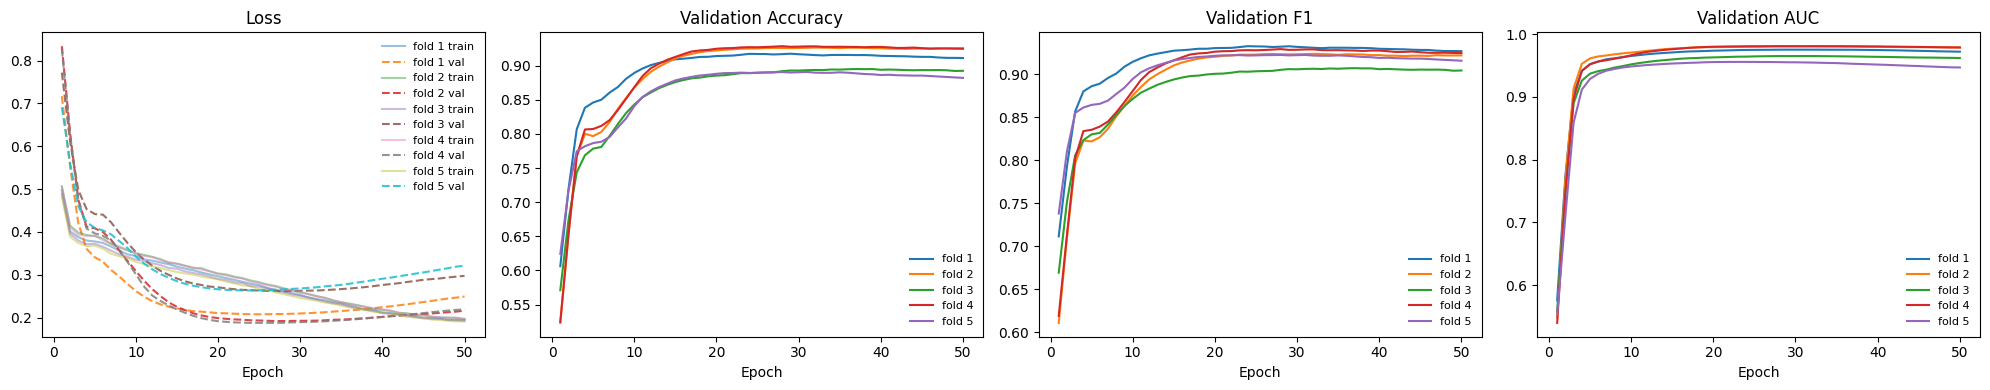

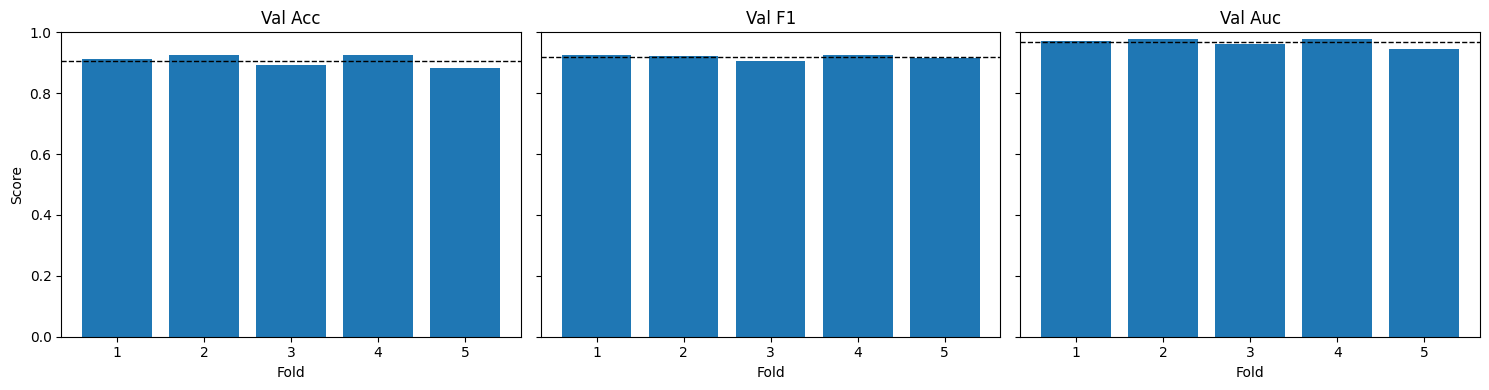

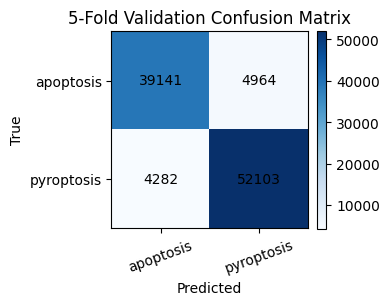

,fold,path,target,pred,prob_class_1,correct
5343,1,/media/capp/TMP2/DeathScope/training/ConvNeXt/...,0,1,0.976103,False
2120,1,/media/capp/TMP2/DeathScope/training/ConvNeXt/...,0,1,0.975976,False
2872,1,/media/capp/TMP2/DeathScope/training/ConvNeXt/...,0,1,0.975970,False
3318,1,/media/capp/TMP2/DeathScope/training/ConvNeXt/...,0,1,0.975925,False
5059,1,/media/capp/TMP2/DeathScope/training/ConvNeXt/...,0,1,0.975888,False
4788,1,/media/capp/TMP2/DeathScope/training/ConvNeXt/...,0,1,0.975887,False
2806,1,/media/capp/TMP2/DeathScope/training/ConvNeXt/...,0,1,0.975802,False
609,1,/media/capp/TMP2/DeathScope/training/ConvNeXt/...,0,1,0.975800,False
3642,1,/media/capp/TMP2/DeathScope/training/ConvNeXt/...,0,1,0.975575,False
2446,1,/media/capp/TMP2/DeathScope/training/ConvNeXt/...,0,1,0.975535,False


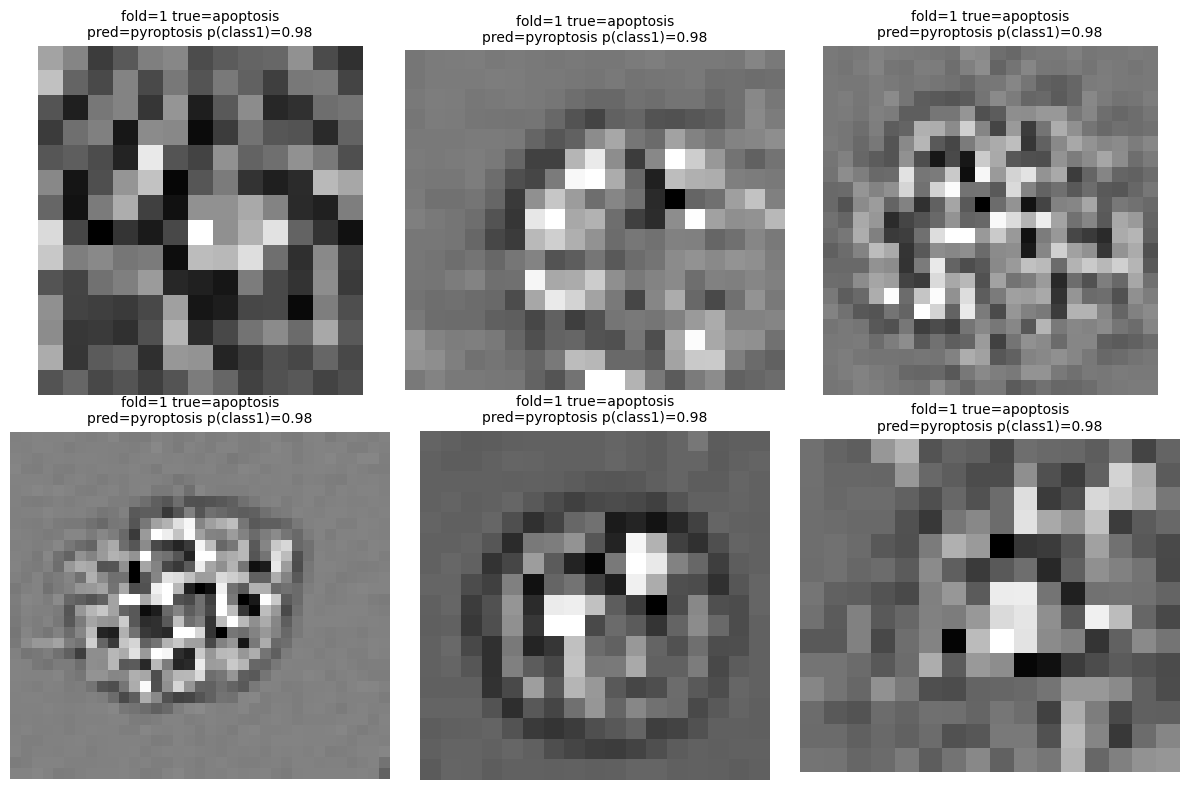

Cross-validation artifacts written to: /media/capp/TMP2/DeathScope/training/ConvNeXt/5fold_cross_validation


In [7]:
device = torch.device(DEVICE)
criterion = nn.CrossEntropyLoss()

fold_final_metrics = []
prediction_rows = []
aggregate_conf_matrix = np.zeros((2, 2), dtype=np.int64)

for fold_number, fold_root in enumerate(fold_roots, start=1):
    fold_run_dir = RUN_DIR / f"fold_{fold_number}"
    best_checkpoint_path = fold_run_dir / "checkpoint_last.pth"
    if not best_checkpoint_path.is_file():
        raise RuntimeError(f"Fold {fold_number} did not produce a last checkpoint: {best_checkpoint_path}")

    _train_loader, val_loader, _train_ds, val_ds = build_fold_dataloaders(fold_root, fold_seed=SEED)
    best_checkpoint = load_checkpoint(best_checkpoint_path, device)
    best_record = dict(best_checkpoint.get("metrics", {}))
    best_model = build_model(ARCHITECTURE, num_classes=len(class_names), pretrained=False).to(device)
    weights_key = "model_ema" if EMA_ENABLED else "model"
    if best_checkpoint.get(weights_key) is None:
        raise ValueError(f"Fold {fold_number}: checkpoint is missing {weights_key} weights.")
    best_model.load_state_dict(best_checkpoint[weights_key])
    best_model.eval()

    val_loss, val_acc, val_f1, val_auc, best_preds, best_probs, best_targets = validate(
        best_model, val_loader, device,
    )
    best_targets = np.asarray(best_targets)
    best_preds = np.asarray(best_preds)
    best_probs = np.asarray(best_probs)
    best_paths = [str(path) for path, _target in val_ds.samples]
    best_record["epoch"] = int(best_checkpoint["epoch"])
    best_record["val_loss"] = val_loss
    best_record["val_acc"] = val_acc
    best_record["val_f1"] = val_f1
    best_record["val_auc"] = val_auc

    conf_matrix = np.zeros((2, 2), dtype=np.int64)
    for target, pred in zip(best_targets, best_preds):
        conf_matrix[int(target), int(pred)] += 1
    aggregate_conf_matrix += conf_matrix

    final_metrics = {
        "fold": fold_number,
        "epoch": int(best_record["epoch"]),
        "evaluation_weights": "ema" if EMA_ENABLED else "model",
        "val_loss": float(best_record["val_loss"]),
        "val_acc": float(best_record["val_acc"]),
        "val_f1": float(best_record["val_f1"]),
        "val_auc": float(best_record["val_auc"]),
        "val_samples": int(len(val_ds)),
        "classes": idx_to_class,
        "confusion_matrix": conf_matrix.tolist(),
    }
    fold_final_metrics.append(final_metrics)

    with (fold_run_dir / "final_metrics.json").open("w", encoding="utf-8") as file:
        json.dump(final_metrics, file, indent=2)

    with (fold_run_dir / "val_predictions.json").open("w", encoding="utf-8") as file:
        json.dump({"targets": best_targets.tolist(), "preds": best_preds.tolist(),
                   "probs": best_probs.tolist(), "classes": idx_to_class}, file, indent=2)

    for path, target, pred, prob in zip(best_paths, best_targets, best_preds, best_probs):
        prediction_rows.append({
            "fold": fold_number,
            "path": path,
            "target": int(target),
            "pred": int(pred),
            "prob_class_1": float(prob),
            "correct": bool(int(target) == int(pred)),
        })

    del best_model, val_loader, _train_loader, _train_ds, val_ds
    if device.type == "cuda":
        torch.cuda.empty_cache()

metrics_df = pd.DataFrame(fold_final_metrics)
metric_summary = {}
for key in ("val_loss", "val_acc", "val_f1", "val_auc"):
    values = pd.to_numeric(metrics_df[key], errors="coerce").dropna()
    metric_summary[f"{key}_mean"] = float(values.mean()) if len(values) else float("nan")
    metric_summary[f"{key}_std"] = float(values.std(ddof=1)) if len(values) > 1 else 0.0

cross_validation_metrics = {
    "k_folds": K_FOLDS,
    "classes": idx_to_class,
    "folds": fold_final_metrics,
    "summary": metric_summary,
    "confusion_matrix_sum": aggregate_conf_matrix.tolist(),
}
with (RUN_DIR / "cross_validation_metrics.json").open("w", encoding="utf-8") as file:
    json.dump(cross_validation_metrics, file, indent=2)
metrics_df.to_csv(RUN_DIR / "cross_validation_metrics.csv", index=False)

predictions_df = pd.DataFrame(prediction_rows)
predictions_df.to_csv(RUN_DIR / "validation_predictions_all_folds.csv", index=False)

display(metrics_df.drop(columns=["confusion_matrix", "classes"]))
display(pd.DataFrame([metric_summary]))

history_path = RUN_DIR / "history_all_folds.csv"
if history_path.is_file():
    history_df = pd.read_csv(history_path)
else:
    history_df = pd.DataFrame(cv_history)

if not history_df.empty:
    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    for fold_number, fold_history in history_df.groupby("fold"):
        axes[0].plot(fold_history["epoch"], fold_history["train_loss"], alpha=0.45, label=f"fold {fold_number} train")
        axes[0].plot(fold_history["epoch"], fold_history["val_loss"], alpha=0.85, linestyle="--", label=f"fold {fold_number} val")
        axes[1].plot(fold_history["epoch"], fold_history["val_acc"], label=f"fold {fold_number}")
        axes[2].plot(fold_history["epoch"], fold_history["val_f1"], label=f"fold {fold_number}")
        axes[3].plot(fold_history["epoch"], fold_history["val_auc"], label=f"fold {fold_number}")
    axes[0].set_title("Loss")
    axes[1].set_title("Validation Accuracy")
    axes[2].set_title("Validation F1")
    axes[3].set_title("Validation AUC")
    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.legend(frameon=False, fontsize=8)
    plt.tight_layout()
    plt.show()

metric_order = ["val_acc", "val_f1", "val_auc"]
fig, axes = plt.subplots(1, len(metric_order), figsize=(15, 4), sharey=True)
for ax, metric_name in zip(axes, metric_order):
    ax.bar(metrics_df["fold"].astype(str), metrics_df[metric_name])
    ax.axhline(metric_summary[f"{metric_name}_mean"], color="black", linewidth=1, linestyle="--")
    ax.set_title(metric_name.replace("_", " ").title())
    ax.set_xlabel("Fold")
    ax.set_ylim(0.0, 1.0)
axes[0].set_ylabel("Score")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(4, 4))
im = ax.imshow(aggregate_conf_matrix, cmap="Blues")
ax.set_xticks([0, 1], [idx_to_class[0], idx_to_class[1]], rotation=20)
ax.set_yticks([0, 1], [idx_to_class[0], idx_to_class[1]])
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("5-Fold Validation Confusion Matrix")
for i in range(2):
    for j in range(2):
        ax.text(j, i, int(aggregate_conf_matrix[i, j]), ha="center", va="center", color="black")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

preview_df = predictions_df.sort_values(["correct", "fold", "prob_class_1"], ascending=[True, True, False])
display(preview_df.head(10))

preview_rows = preview_df.head(6).to_dict(orient="records")
if preview_rows:
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    axes = axes.ravel()
    for ax, row in zip(axes, preview_rows):
        image = cv2.imread(row["path"], cv2.IMREAD_GRAYSCALE)
        ax.imshow(image, cmap="gray")
        ax.set_title(
            f"fold={row['fold']} true={idx_to_class[row['target']]}\npred={idx_to_class[row['pred']]} p(class1)={row['prob_class_1']:.2f}",
            fontsize=10,
        )
        ax.axis("off")
    for ax in axes[len(preview_rows):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

print(f"Cross-validation artifacts written to: {RUN_DIR}")
